# Quantum Metal tutorial 2.22 — 100 qubits on a staggered grid, generated programmatically (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial
`docs/tut/2-From-components-to-chip/2.22-Design-100-qubits-programmatically.ipynb`, © Qiskit Metal contributors,
Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>); spec `docs/designs/metal/tut222_100q_grid.md`. We
distribute the rebuild under GPL-3.0. A 10 × 10 grid of `TransmonPocket` qubits (Metal defaults, four connection
pads B0–B3, orientation −90°) on a brick lattice: 3 mm pitch, odd columns shifted up by 1.5 mm. Meandered buses join
each qubit to the one above (`CU_x_y`, B0 → B3, 7.0 / 7.5 mm alternating by row, 90 of them) and to the up-right
neighbour (`CS_x_y`, B1 → B2, 6.0 / 6.5 mm, 86), so no qubit sees two equal buses. No launchpads, readouts or
control lines — the tutorial: "not a practical design given the lack of readouts or control lines to the qubits,
just an example for how to make a design algorithmically".

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options and the buses follow
Metal's own meanders; the chip, the stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial 2.22 | Quantcore PDK rebuild |
|---|---|---|
| chip | (N + 1)·3 = 33 mm square, centred at (13.5, 14.25) mm | the same 33 × 33 mm box with the QCT die frame (Designer = Metal + (3000, 2250) µm) |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| pads | none | none (nothing for the pad rule to move) |
| junctions | `FakeJunction_01` GDS cell; its LOM uses 12.31 nH + 2 fF (a value, not a target) | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF), all 100 identical |
| cheese | **Metal's GDS cheese** (the tutorial exports `NxN_Chip.gds` with `no_cheese.buffer = 50um`: 25 µm holes every 100 µm over the ground) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=50)`) |
| buses | `RouteMeander` (fillet 99 µm, asymmetry −700 / −200 µm) | qcc fixed-length routes on Metal's own meander corner points (computed by running the tutorial's loops in a headless Metal design) |
| placement | the grid sits 0.34 mm right of the chip centre | content centred in the die (shift printed in step 7) |

**Kept exactly:** the tutorial's two generator loops, run twice — once in a headless Metal design (step 6, about
15 s) to get every `RouteMeander`'s own corner points, and once here with `metal:TransmonPocket` and qcc routes on
those corner points (fillet 99 µm, 10 / 6 µm CPW, Metal's defaults) — so every qubit, pin and bus path is Metal's
(up to the centring shift). The source's typo `loc_w` on B3 is kept (harmless: `loc_W` defaults to +1).

**Not reproduced:** the tutorial's Q3D + LOM run (Ansys; it fails in the stored notebook without Windows) and its
fake junction GDS cells. The LOM here is qcc's (step 10) and the Q3D jobs are exported (step 11).

The notebook goes step by step: PDK → die → (pads) → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary. The chip is large (100
qubits, 176 buses, 33 mm): each full rebuild takes tens of seconds, so the intermediate snapshots are few.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
import logging, warnings
N_x = N_y = 10
X0, Y0 = 3000, 2250                              # Metal's chip spans x −3…30 mm, y −2.25…30.75 mm
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PADS = dict(B0=dict(loc_W=-1, loc_H=-1, pad_width="75um"), B1=dict(loc_W=-1, loc_H=+1, pad_width="120um"),
            B2=dict(loc_W=+1, loc_H=-1, pad_width="120um"), B3=dict(loc_w=+1, loc_H=+1, pad_width="90um"))

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 33 mm box gets the QCT frame; there are no pads for the pad rule; the 100 qubits get the PDK nominal trilayer junction; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal's 33 mm chip spans
x −3…30 mm, y −2.25…30.75 mm, so `P(x, y)` = Metal + (3000, 2250).

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (step 14), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=50)}` hands the build Metal's rule (25 µm squares every 100 µm, 50 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

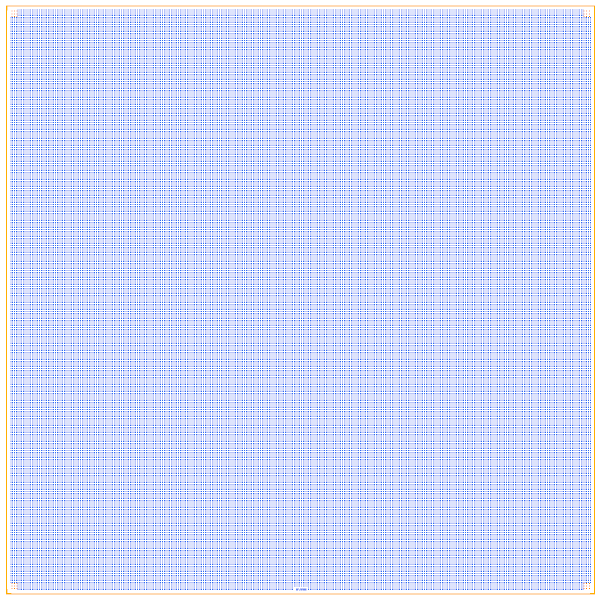

WindowsPath('examples/designs/metal/tut222_100q_grid_step_die.png')

In [4]:
d = Designer("tut222_100q_grid", box=(0, 0, 33000, 33000), chip={"name_chip": "MetalTut222", "cheese": metal_cheese_rule(buffer=50)},
             live=LIVE)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "tut222_100q_grid_step_die.png", size=(600, 600), width=300)

## 4 · Pads

Tutorial 2.22 has no launchpads, readouts or control lines, so the PDK pad rule (outer etch edge 25 µm from the die
edge) has nothing to place; `pads_md(d)` in step 7 confirms there are none.

## 5 · Components: 100 TransmonPockets

**The qubits.** The tutorial's first loop: `metal:TransmonPocket` with Metal's defaults (pads 455 µm, pocket
650 µm), orientation −90°, at (3x, 3y + 1.5·(x mod 2)) mm, with four connection pads B0–B3 of widths 75 / 120 / 120 /
90 µm (so no qubit sees two equal buses).

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The tutorial's LOM value (12.31 nH) is not a frequency target, so every qubit gets the PDK
nominal junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ,
L_J 6.73 nH, C_J 15 fF).

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


100 qubits; Q_0_0 ports: ['B0', 'B1', 'B2', 'B3', 'squid_a', 'squid_b']


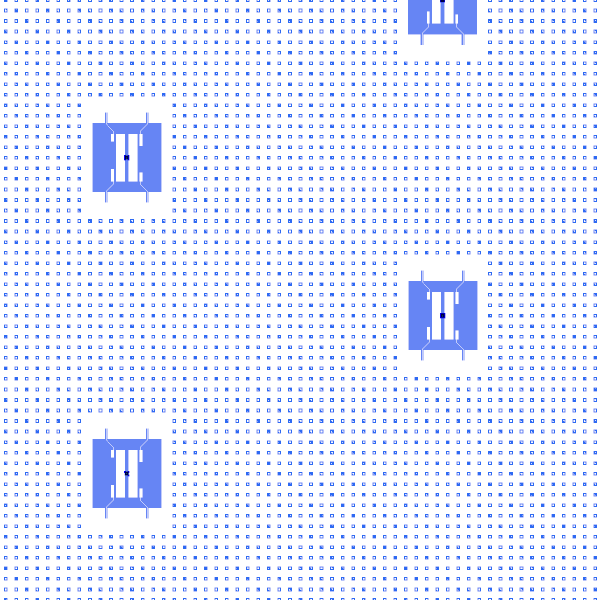

WindowsPath('examples/designs/metal/tut222_100q_grid_step_parts.png')

In [5]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    q = {f"Q_{x}_{y}": d.add(f"Q_{x}_{y}", "metal:TransmonPocket", at=P(x * 3000, y * 3000 + (x % 2) * 1500),
                             rot=-90, junction=JUNCTION, **JJ_PARAMS, connection_pads=PADS)
         for x in range(N_x) for y in range(N_y)}
print(len(q), "qubits; Q_0_0 ports:", sorted(q["Q_0_0"].ports))
snap(d, OUT / "tut222_100q_grid_step_parts.png", box=P(-1200, -1200) + P(4500, 4500), size=(600, 600), width=300)

## 6 · Routes: Metal's own meanders

**Metal's corner points.** The tutorial's second loop creates a `RouteMeander` per bus (`cu`: the "upward" bus B0 →
B3, 7.0 / 7.5 mm, lead 0.5 / 0.25 mm, asymmetry −700 µm; `cs`: the "sideways" bus B1 → B2, 6.0 / 6.5 mm, lead
0.3 / 0.25 mm, asymmetry −200 µm). Running both loops in a headless Metal design gives every meander's own corner
points (`get_points()`), so the rebuild can lay its routes exactly on Metal's paths.

In [6]:
def cu(x, y):  # the tutorial's "upward" bus (or None)
    return dict(total_length=f"{7 + (y % 2) * 0.5}mm", lead=dict(start_straight="0.5mm", end_straight="0.25mm"),
                meander=dict(asymmetry="-700um"), ends=((f"Q_{x}_{y}", "B0"), (f"Q_{x}_{y + 1}", "B3"))) \
        if y < N_y - 1 else None

def cs(x, y):  # the tutorial's "sideways" bus (or None)
    return dict(total_length=f"{6 + (y % 2) * 0.5}mm", lead=dict(start_straight="0.3mm", end_straight="0.25mm"),
                meander=dict(asymmetry="-200um"), ends=((f"Q_{x}_{y}", "B1"), (f"Q_{x + 1}_{y + x % 2}", "B2"))) \
        if x < N_x - 1 and not (x % 2 and y == N_y - 1) else None

# the tutorial's loops in a headless Metal design: every RouteMeander's corner points (µm, Metal frame)
os.environ["QISKIT_METAL_HEADLESS"] = "True"
logging.disable(logging.WARNING); warnings.simplefilter("ignore")
from qiskit_metal import designs
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
mdesign = designs.DesignPlanar()
for x in range(N_x):
    for y in range(N_y):
        TransmonPocket(mdesign, f"Q_{x}_{y}", dict(pos_x=f"{x * 3000}um", pos_y=f"{y * 3000 + (x % 2) * 1500}um",
                                                   orientation="-90", connection_pads=PADS))
PATHS, BUSES = {}, {}
for x in range(N_x):
    for y in range(N_y):
        for name, opt in ((f"CU_{x}_{y}", cu(x, y)), (f"CS_{x}_{y}", cs(x, y))):
            if opt is None:
                continue
            (q0, p0), (q1, p1) = opt.pop("ends")
            r = RouteMeander(mdesign, name, options=dict(fillet="99um", **opt, pin_inputs=dict(
                start_pin=dict(component=q0, pin=p0), end_pin=dict(component=q1, pin=p1))))
            PATHS[name] = [(1000 * float(a), 1000 * float(b)) for a, b in r.get_points()]
            BUSES[name] = (q0, p0, q1, p1, 1000 * float(opt["total_length"][:-2]))
logging.disable(logging.NOTSET)
print(len(PATHS), "Metal buses;", sum(len(v) for v in PATHS.values()), "corner points")

176 Metal buses; 3676 corner points


**The qcc routes.** Each bus becomes a fixed-length route (`meander=length`) between the same two pins, with
Metal's interior corner points as waypoints (fillet 99 µm as the turn radius, 10 / 6 µm CPW). The 0.05 µm over Metal's
`total_length` keeps the router on Metal's path (it only adds that much). In the LOM each bus is a λ/2 `TLres` open
at both pads.

**Sim groups:** Q_0_0 alone (the tutorial's Q3D case: the box cuts its four buses, as its open terminations do) and
the Q_0_0–Q_0_1 pair with their bus, both Q3D C-matrix jobs with a 300 µm margin. The full build (and its snapshot)
waits for step 7.

In [7]:
with d.batch():
    # fixed-length meanders (λ/2 buses in the LOM) on Metal's corner points; the 0.05 µm over Metal's total_length
    # keeps the router on Metal's path
    for name, (q0, p0, q1, p1, length) in BUSES.items():
        d.route(name, getattr(q[q0], p0), getattr(q[q1], p1), meander=length + 0.05, r=99, a=10, b=6,
                nodes=[P(x, y) for x, y in PATHS[name][1:-1]])
# FEM: Q_0_0 alone (the tutorial's Q3D), and the Q_0_0–Q_0_1 pair with their bus
d.sim_group("Q_0_0", ["Q_0_0"], margin_um=300, analyses=["q3d_cmatrix"])
d.sim_group("Q00_CU00_Q01", ["Q_0_0", "CU_0_0", "Q_0_1"], margin_um=300, analyses=["q3d_cmatrix"])
print(len(d.data["routes"]), "routes;", sorted(d.data["sim_groups"]))

176 routes; ['Q00_CU00_Q01', 'Q_0_0']


## 7 · Centre the content and save

The PDK wants the chip content centred in the die. Metal's grid sits off its own chip's centre (the qubit pockets
and meanders reach further to the right than to the left), so `center_in_die` — which measures the bounding box of
everything placed and shifts every qubit position and route waypoint — moves the whole grid left by about 0.34 mm.
Then the chip is built (the first full build: 100 qubits, 176 buses) and saved: the JSON is the deliverable.

content shifted by (-336.7, 0.0) µm
CU 90 buses, lengths (µm): [7000.0, 7500.0]
CS 86 buses, lengths (µm): [6000.0, 6500.1]


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

<Designer tut222_100q_grid: 100 instances, 176 routes, live=False> → examples\designs\metal\tut222_100q_grid.json


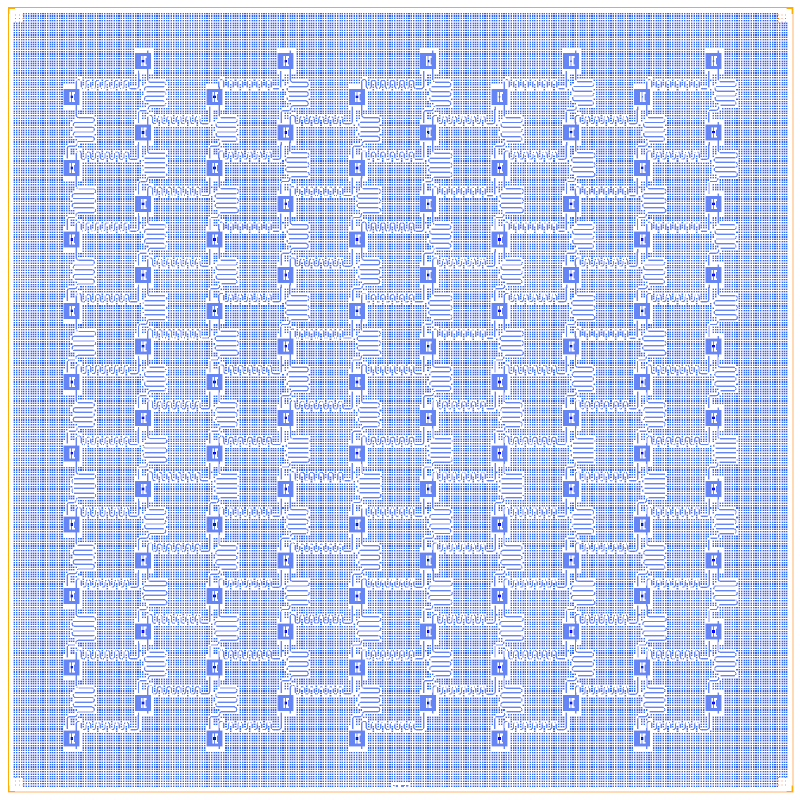

WindowsPath('examples/designs/metal/tut222_100q_grid_step_routes.png')

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
L = d.result.route_lengths()
for fam in ("CU", "CS"):
    vals = sorted({round(v, 1) for k, v in L.items() if k.startswith(fam)})
    print(fam, sum(k.startswith(fam) for k in L), "buses, lengths (µm):", vals)
display(Markdown(pads_md(d)))
DESIGN = d.save(OUT / "tut222_100q_grid.json")
print(d, "→", DESIGN)
snap(d, OUT / "tut222_100q_grid_step_routes.png", size=(800, 800), width=400)

## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, no overlaps, and 248 `dangling_port` warnings: the 200 junction attachment
points (`squid_a` / `squid_b`, drawn by the cell) and the 48 pads the generator leaves free on the grid edges (B0 on
the top row, B3 on the bottom row, B2 on the left column and the four even-column bottom qubits, B1 on the right
column and the four odd-column top qubits: Metal draws them as short open leads, and so does the rebuild); **no PDK
design warnings** (no pads, the nominal junction is in the R_n window, no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 248 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 248 | Q_0_0.B2 is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 75, rows 1000, clearance 50, edge 200 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 100 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocket` gives two floating pads (`island1` /
`island2`) with the junction, and a coupler node per connection pad; every bus between two pads is a λ/2 `TLres`
(open at both pads). Whole chip: 100 qubits and 176 buses. The table lists the first nodes and branches only (the
full netlist is in `lb`), then Q_0_0's port map.

In [10]:
from collections import Counter
lb = d.lom()
md_ = netlist_md(lb)
print(md_.splitlines()[0])
display(Markdown("\n".join(md_.splitlines()[:40]) + "\n\n…"))
print(Counter(b.type for b in lb.model.branches.values()))
print({k: v for k, v in lb.port_map.items() if k.startswith("Q_0_0.")})

**425 nodes · 1776 branches · 0 controls · 48 unconnected ports**


**425 nodes · 1776 branches · 0 controls · 48 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q_0_0.island1` | `Q_0_0.island1` |
| `Q_0_0.island2` | `Q_0_0.island2` |
| `Q_0_0.B0` | `Q_0_0.B0`, `Q_0_1.B3` |
| `Q_0_0.B1` | `Q_0_0.B1`, `Q_1_0.B2` |
| `Q_0_0.B2` | `Q_0_0.B2` |
| `Q_0_0.B3` | `Q_0_0.B3` |
| `Q_0_1.island1` | `Q_0_1.island1` |
| `Q_0_1.island2` | `Q_0_1.island2` |
| `Q_0_1.B0` | `Q_0_1.B0`, `Q_0_2.B3` |
| `Q_0_1.B1` | `Q_0_1.B1`, `Q_1_1.B2` |
| `Q_0_1.B2` | `Q_0_1.B2` |
| `Q_0_2.island1` | `Q_0_2.island1` |
| `Q_0_2.island2` | `Q_0_2.island2` |
| `Q_0_2.B0` | `Q_0_2.B0`, `Q_0_3.B3` |
| `Q_0_2.B1` | `Q_0_2.B1`, `Q_1_2.B2` |
| `Q_0_2.B2` | `Q_0_2.B2` |
| `Q_0_3.island1` | `Q_0_3.island1` |
| `Q_0_3.island2` | `Q_0_3.island2` |
| `Q_0_3.B0` | `Q_0_3.B0`, `Q_0_4.B3` |
| `Q_0_3.B1` | `Q_0_3.B1`, `Q_1_3.B2` |
| `Q_0_3.B2` | `Q_0_3.B2` |
| `Q_0_4.island1` | `Q_0_4.island1` |
| `Q_0_4.island2` | `Q_0_4.island2` |
| `Q_0_4.B0` | `Q_0_4.B0`, `Q_0_5.B3` |
| `Q_0_4.B1` | `Q_0_4.B1`, `Q_1_4.B2` |
| `Q_0_4.B2` | `Q_0_4.B2` |
| `Q_0_5.island1` | `Q_0_5.island1` |
| `Q_0_5.island2` | `Q_0_5.island2` |
| `Q_0_5.B0` | `Q_0_5.B0`, `Q_0_6.B3` |
| `Q_0_5.B1` | `Q_0_5.B1`, `Q_1_5.B2` |
| `Q_0_5.B2` | `Q_0_5.B2` |
| `Q_0_6.island1` | `Q_0_6.island1` |
| `Q_0_6.island2` | `Q_0_6.island2` |
| `Q_0_6.B0` | `Q_0_6.B0`, `Q_0_7.B3` |
| `Q_0_6.B1` | `Q_0_6.B1`, `Q_1_6.B2` |

…

Counter({'C': 1500, 'TLres': 176, 'JJ': 100})
{'Q_0_0.squid_a': 'Q_0_0.island2', 'Q_0_0.squid_b': 'Q_0_0.island1', 'Q_0_0.B0': 'Q_0_0.B0', 'Q_0_0.B1': 'Q_0_0.B1', 'Q_0_0.B2': 'Q_0_0.B2', 'Q_0_0.B3': 'Q_0_0.B3'}


## 10 · LOM simulation

QuCat cannot solve 100 qubits and 176 buses at once, so: Q_0_0 alone (the tutorial's LOM case, all four pads open:
its four buses are outside the selection), then the corner qubit with its two neighbours and their buses
(Q_0_0 –CU_0_0– Q_0_1, Q_0_0 –CS_0_0– Q_1_0) for the bus frequencies and the static ZZ. QuCat gives the linear
normal modes; the tables under them have the QuTiP dressed values (f_q includes the anharmonic shift).

With the PDK junction (6.73 nH, 15 fF) Q_0_0 sits near 6.9 GHz, below the 8.4–9.5 GHz λ/2 buses (the tutorial's
Metal LOM *assumes* 6.0 / 6.2 / 6.4 GHz buses; the drawn 6–7.5 mm λ/2 buses are higher). Two neighbours whose bus pads
have equal widths (B1 / B2, both 120 µm) can hybridise through their bus (ZZ "hybridised", not defined). All 100
qubits share one junction, so the grid has no frequency plan beyond the bus lengths.

In [11]:
single = simulate_groups(d, {"Q_0_0": ["Q_0_0"]})
display(Markdown("**Q_0_0 (pads open), QuCat normal mode:**\n\n" + modes_md(single["Q_0_0"]) + "\n\n" + groups_md(single)))
pairs = simulate_groups(d, {"Q_0_0+CU_0_0+Q_0_1": ["Q_0_0", "CU_0_0", "Q_0_1"],
                            "Q_0_0+CS_0_0+Q_1_0": ["Q_0_0", "CS_0_0", "Q_1_0"]}, max_modes=3)
for g, r in pairs.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))
display(Markdown(groups_md(pairs)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pairs)))

**Q_0_0 (pads open), QuCat normal mode:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_0_0 | qubit | 7.2081 | 0 | 267.6 | J_Q_0_0 1.00 |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q_0_0 | Q_0_0 | 6.9295 | -294.6 | – | – | – | – |

**Q_0_0+CU_0_0+Q_0_1, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_0_1 | qubit | 7.1716 | 0 | 189.8 | J_Q_0_1 0.83, J_Q_0_0 0.16 |
| Q_0_0 | qubit | 7.1849 | 0 | 193.2 | J_Q_0_0 0.84, J_Q_0_1 0.16 |
| CU_0_0 | resonator | 8.3579 | 0 | 0.0 | CU_0_0 0.99 |

**Q_0_0+CS_0_0+Q_1_0, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_1_0 | qubit | 7.1473 | 0 | 136.2 | J_Q_1_0 0.61, J_Q_0_0 0.38 |
| Q_0_0 | qubit | 7.1593 | 0 | 138.6 | J_Q_0_0 0.61, J_Q_1_0 0.39 |
| CS_0_0 | resonator | 9.5138 | 0 | 0.0 | CS_0_0 0.99 |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q_0_0+CU_0_0+Q_0_1 | Q_0_1 | 6.8975 | -287.4 | CU_0_0 | 8.3551 | 0 | -2.2 |
|  | Q_0_0 | 6.9082 | -294.1 | – | – | – | – |
| Q_0_0+CS_0_0+Q_1_0 | Q_1_0 | 6.8747 | 10.02 | CS_0_0 | 9.5113 | 0 | -2.08 |
|  | Q_0_0 | 6.8844 | -9.529 | – | – | – | – |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q_0_0+CU_0_0+Q_0_1 | Q_0_0-Q_0_1 | 129.6 | yes | no |
| Q_0_0+CS_0_0+Q_1_0 | Q_0_0-Q_1_0 | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for the two sim groups: `Q_0_0` (the tutorial's Q3D of one qubit; the box cuts its four
buses, as its open terminations do) and `Q00_CU00_Q01` (Q_0_0 with Q_0_1 and the 7 mm bus between them: the pad-to-bus
capacitances that set the coupling).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN, ["Q_0_0", "Q00_CU00_Q01"])
display(Markdown(jobs_md(jobs)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q_0_0 | `build/jobs/tut222_100q_grid_Q_0_0_q3d_cmatrix` | 1 · junction · `Q_0_0.junction`<br>2 · edge · `CS_0_0`<br>3 · edge · `CU_0_0` | `Q_0_0.island2`, `CS_0_0`, `CU_0_0`, `Q_0_0.island1` |
| Q00_CU00_Q01 | `build/jobs/tut222_100q_grid_Q00_CU00_Q01_q3d_cmatrix` | 1 · junction · `Q_0_0.junction`<br>2 · junction · `Q_0_1.junction`<br>3 · waveguide · `Q_0_0.B0`<br>4 · waveguide · `Q_0_1.B3`<br>5 · edge · `CS_0_0`<br>6 · edge · `CS_0_1`<br>7 · edge · `CU_0_1` | `Q_0_0.island2`, `Q_0_1.island2`, `Q_0_0.B0`, `Q_0_1.B3`, `CS_0_0`, `CS_0_1`, `CU_0_1`, `Q_0_0.island1`, `Q_0_1.island1` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q_0_0', 'Q00_CU00_Q01'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {f"{g} · q3d": v for g, v in jobs.items()})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q_0_0 · q3d, Q00_CU00_Q01 · q3d: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q_0_0's main pads, `pad_width` 455 µm (Metal's default) → 400 µm — rebuild, re-run
the LOM of Q_0_0 alone and compare. Narrower pads have less capacitance: E_C grows, so f_q and |α| go up. (The copy
holds the whole chip, so its LOM build takes a few seconds even for one qubit.)

In [15]:
d2 = design_copy(DESIGN)
d2["Q_0_0"].set(pad_width=400)                   # Metal default 455 → 400 µm
after = simulate_groups(d2, {"Q_0_0": ["Q_0_0"]})
display(Markdown(params_delta_md(single, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q_0_0: Q_0_0.f_q_GHz` | 6.9295 | 7.1398 | +0.2103 |
| `Q_0_0: Q_0_0.alpha_MHz` | -294.64 | -314.75 | -20.12 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** Tutorial 2.22 exports its chip with Metal's GDS renderer (`chip_gds.export_to_gds("NxN_Chip.gds")`) after setting `chip_gds.options["no_cheese"]["buffer"] = "50um"`, and the renderer cheeses the ground by default (`cheese.view_in_file = {main: {1: True}}`: 25 µm squares every 100 µm, none within 200 µm of the chip edge). So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (step 3: `metal_cheese_rule(buffer=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\tut222_100q_grid.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 76860 |
| 2/0 | JJ_STRAIGHT | 100 |
| 3/0 | M3 | 76838 |
| 4/0 | JJ_BENT | 100 |
| 50/0 | HSQ | 200 |
| 51/0 | SPACER_1 | 200 |
| 52/0 | SPACER_2 | 200 |
| 53/0 | SPACER_3 | 200 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 76835 holes on the mask.

→ `build/tut222_100q_grid_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's last screenshot); the bottom-left corner (Q_0_0, Q_0_1, Q_1_0 and their
buses); one qubit with its four pads; a trilayer junction; the **fab mask** at the corner (1/0 etch with Metal's
cheese reproduced, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on
1000/0, alignment grid on 1001/0). Positions are read from the design (after the centring shift).

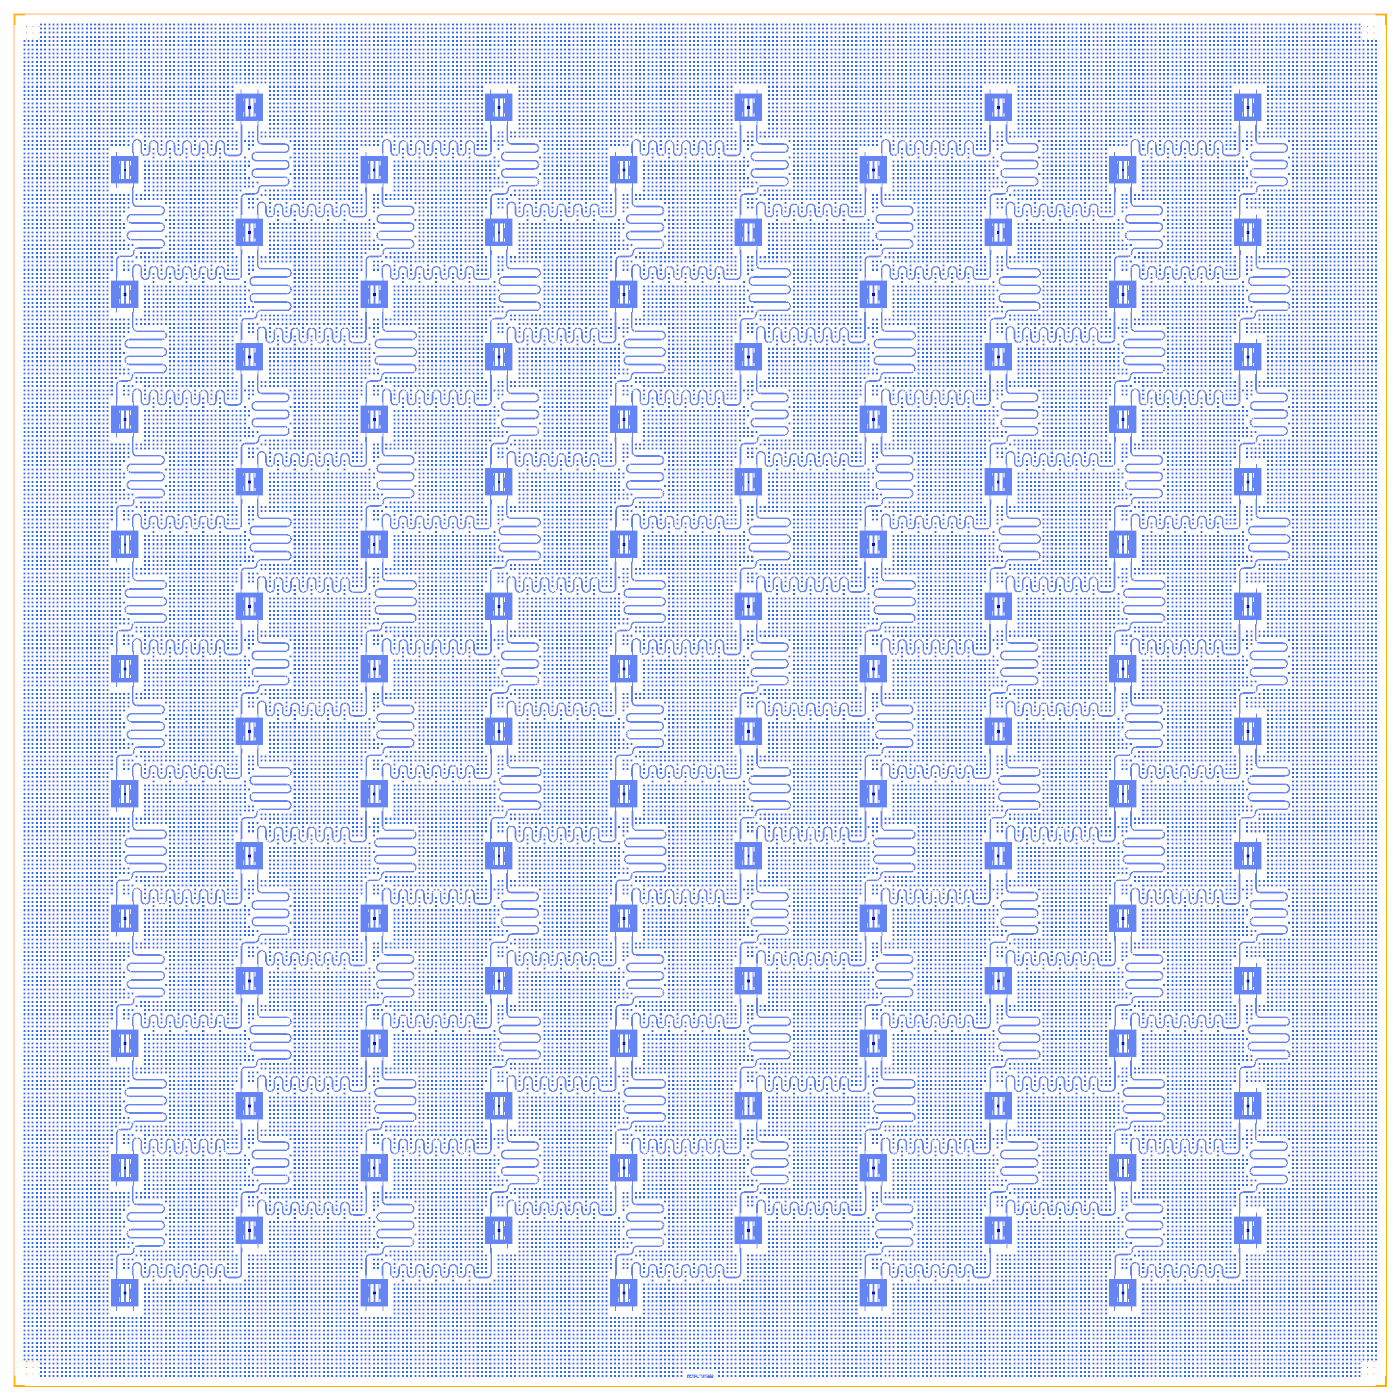

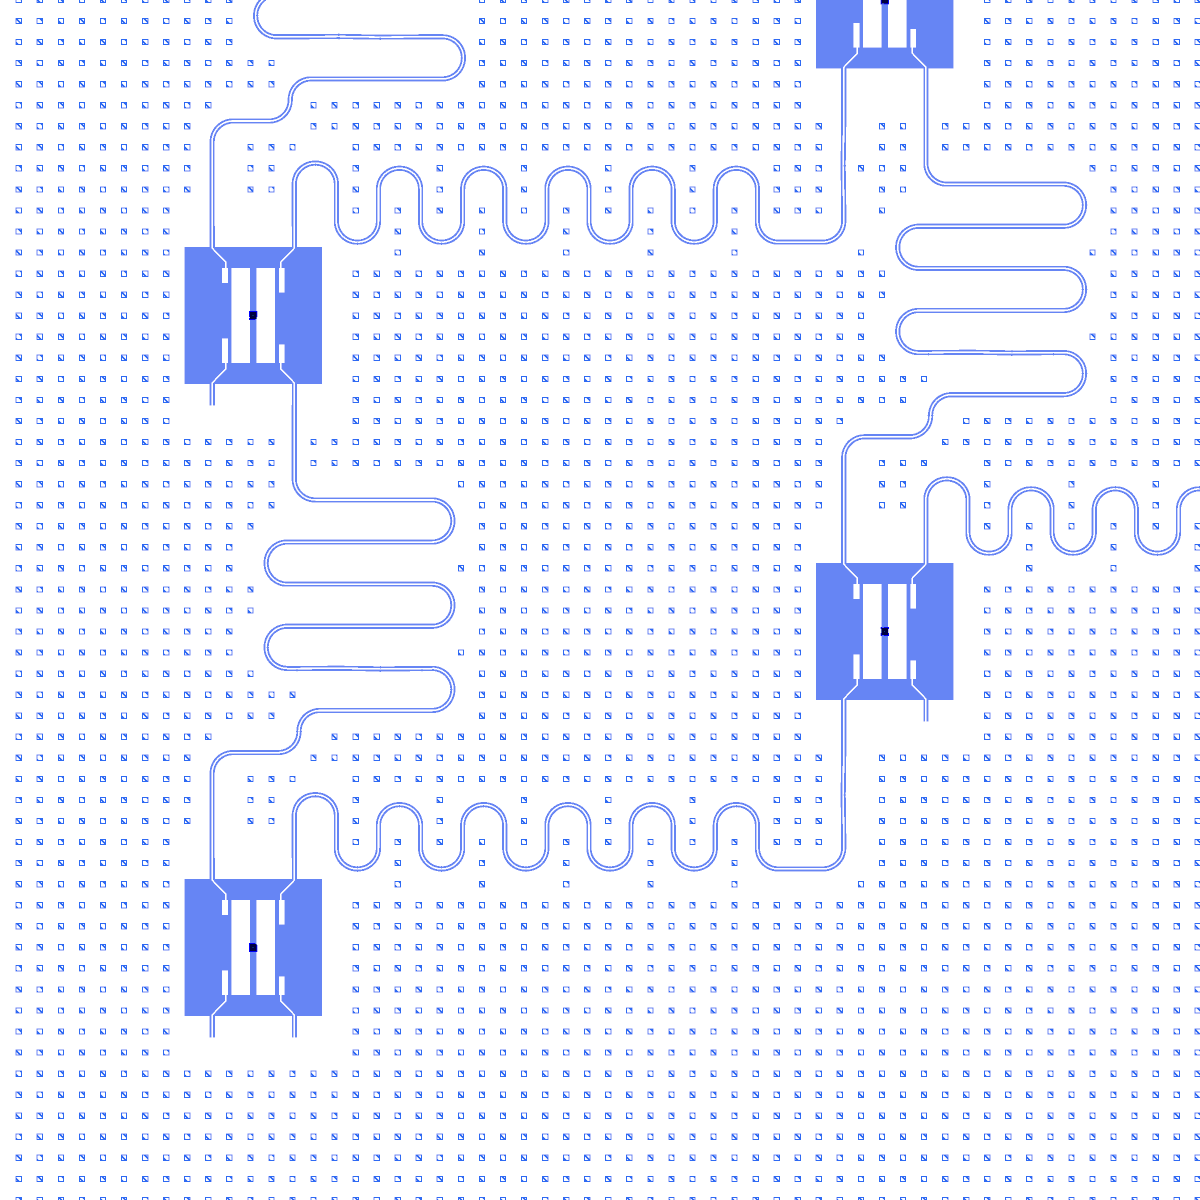

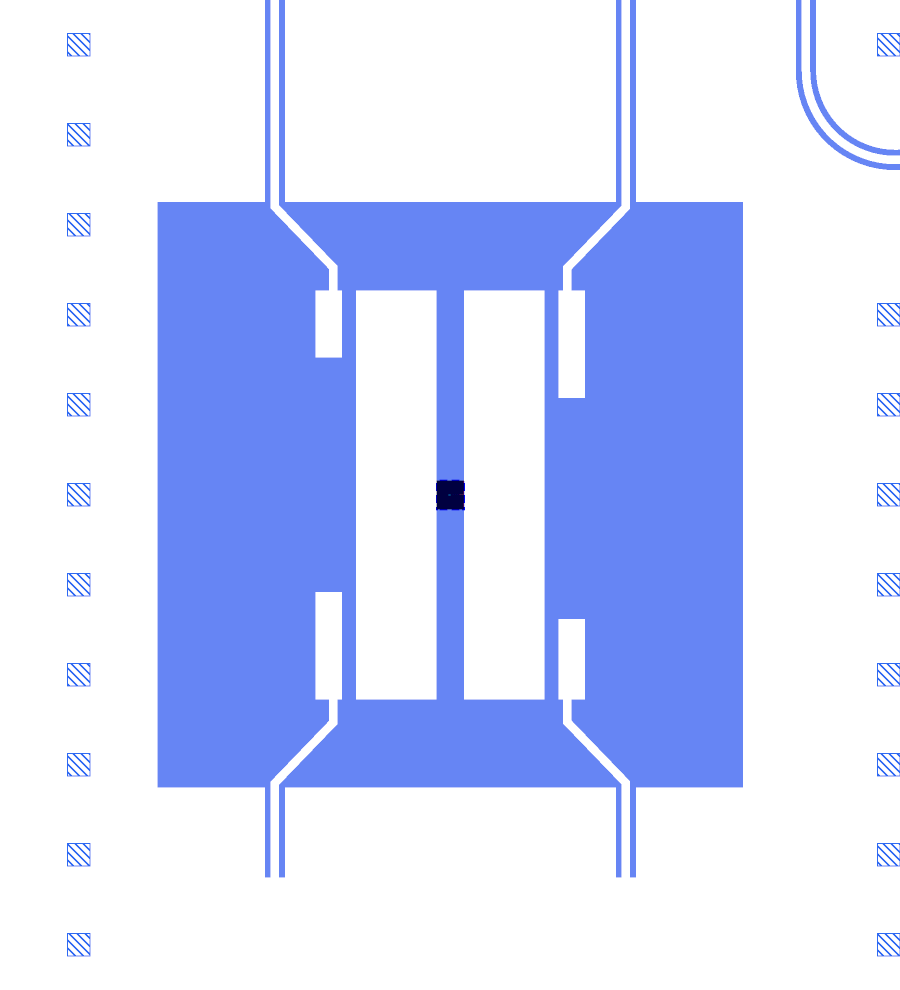

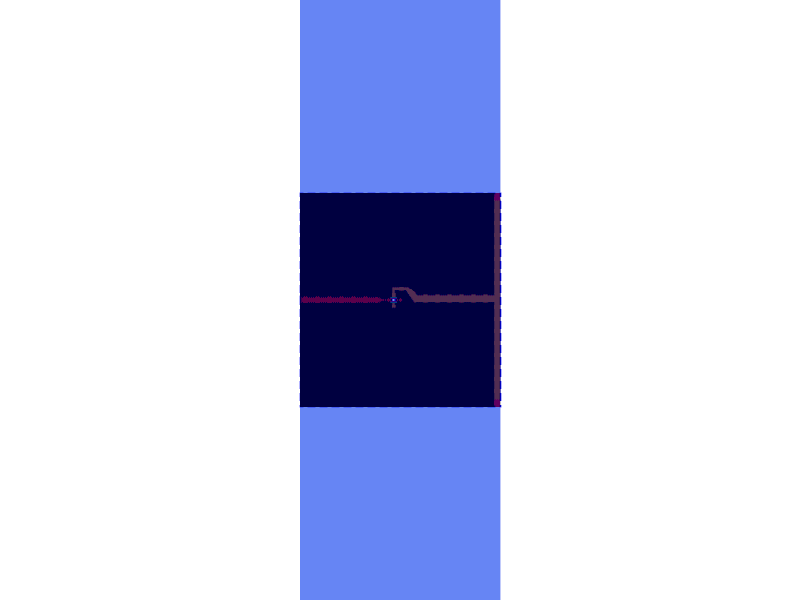

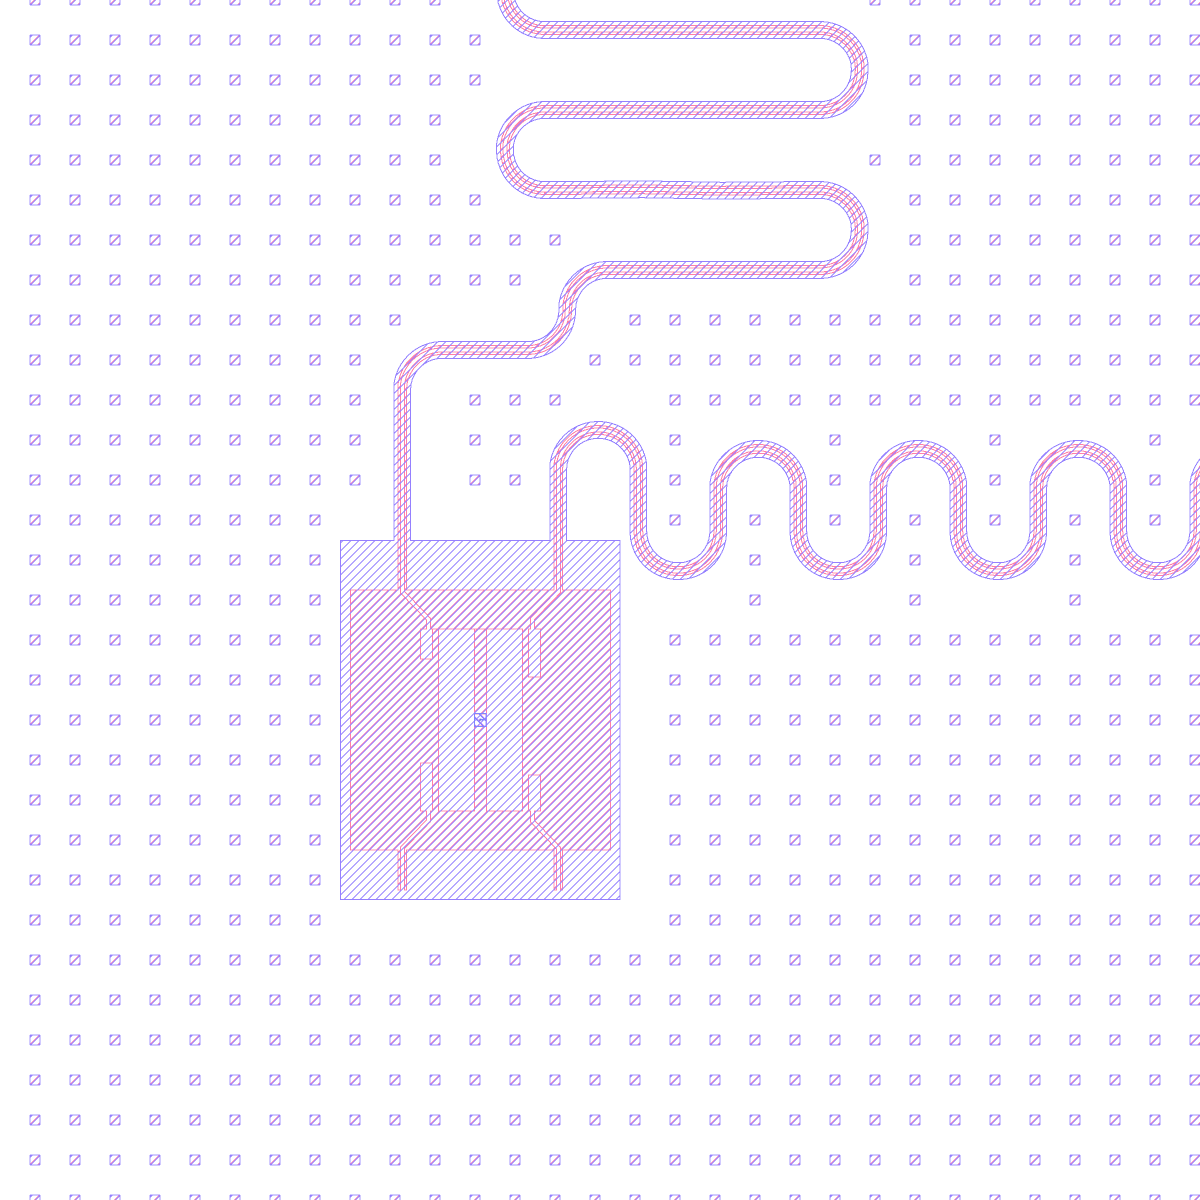

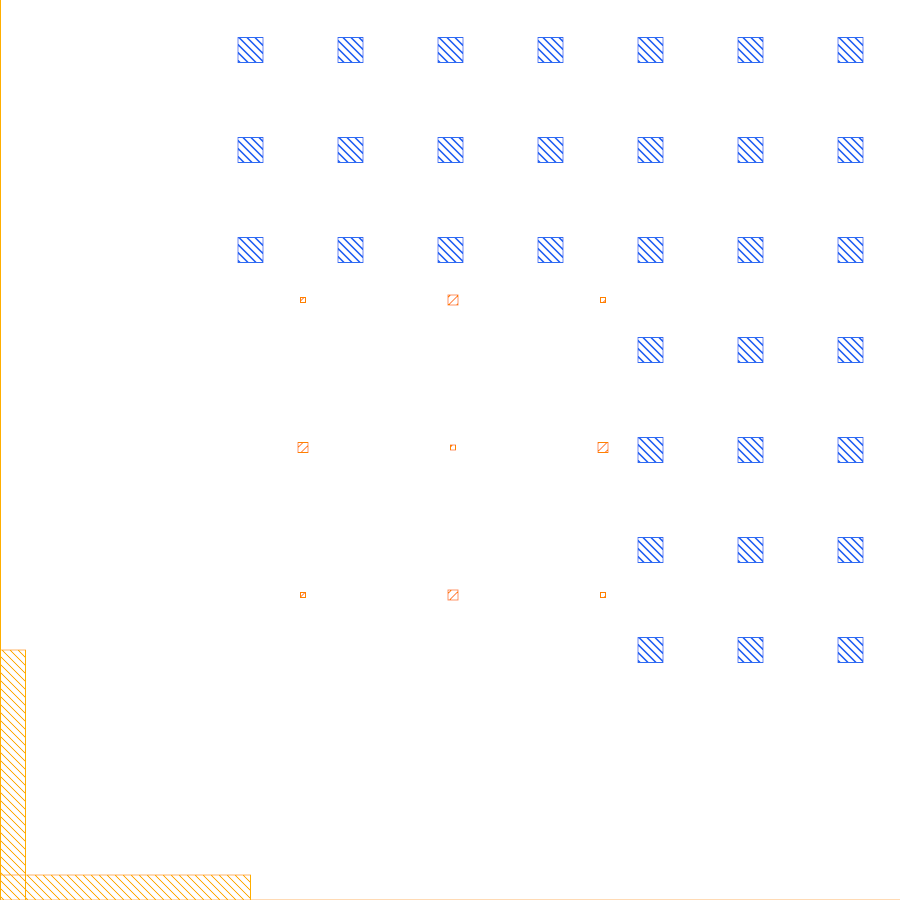

In [17]:
qx, qy = d.data["instances"]["Q_0_0"]["place"]["at"]
show_snapshot(d, OUT / "tut222_100q_grid.png", size=(1400, 1400))
show_snapshot(d, OUT / "tut222_100q_grid_corner.png", box=(qx - 1200, qy - 1200, qx + 4500, qy + 4500), size=(1200, 1200),
              width=520)
show_snapshot(d, OUT / "tut222_100q_grid_q00.png", box=(qx - 500, qy - 550, qx + 500, qy + 550), size=(900, 990), width=400)
show_snapshot(d, OUT / "tut222_100q_grid_jj.png", box=(qx - 60, qy - 45, qx + 60, qy + 45), size=(800, 600), width=300)
snap_file(Path("build") / "tut222_100q_grid_fab.oas", OUT / "tut222_100q_grid_cheese.png",
          box=(qx - 1200, qy - 1200, qx + 1800, qy + 1800), size=(1200, 1200), width=480)
show_snapshot(d, OUT / "tut222_100q_grid_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | the tutorial's two generator loops: every qubit with its options and pads, every bus on Metal's own meander corner points with Metal's lengths (CU 7.0 / 7.5 mm, CS 6.0 / 6.5 mm), the free edge pads; the original's GDS cheese (drawn by the build) |
| PDK changes | QCT frame on the 33 mm box; sapphire stack; trilayer junctions (PDK nominal); the grid centred in the die (shifted by −336.7 µm in x); no pads to place |
| differs | f_q with the PDK junction instead of the tutorial's 12.31 nH LOM value |
| LOM (this run) | Q_0_0 alone 6.930 GHz dressed (QuCat 7.208), α −295 MHz; CU_0_0 8.355 GHz, CS_0_0 9.511 GHz dressed, χ −2.2 / −2.1 MHz; static ZZ Q_0_0–Q_0_1 130 kHz, Q_0_0–Q_1_0 hybridised (equal 120 µm B1 / B2 pads); iterate (`pad_width` 455 → 400 µm): f_q +210 MHz, α −20 MHz |
| PDK design warnings | none |
| open | the filled 3/0 keep-out closes every bus loop, so the plaquettes inside the bus rings (65 % of the die) get no cheese; the FEM jobs are exported, not solved (`RUN_FEM = False`) |